# Offline Crop Disease Detector (Uncertainty-Aware, On-Device)

**Goal:** Classify plant leaf diseases from a phone photo, run fully offline (TFLite), and say *"uncertain, ask an expert"* instead of guessing.

**Pipeline:** Data -> MobileNetV2 transfer learning -> evaluation -> confidence/abstention -> TFLite quantization -> Streamlit app + Docker -> deploy (Hugging Face Spaces / Android).

Run on **Google Colab** (Runtime > Change runtime type > GPU).

> Honest limitation: PlantVillage images are lab-style (plain background). Field photos are harder. Section 10 shows how to add PlantDoc/your own photos to close that gap.

## 1. Setup

In [1]:
!pip -q install tensorflow-datasets scikit-learn seaborn streamlit pillow
import os, json, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

SEED, IMG, BATCH = 42, 224, 32
tf.keras.utils.set_random_seed(SEED)
print(tf.__version__, "GPU:", tf.config.list_physical_devices("GPU"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 94.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 122.9 MB/s eta 0:00:00
2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
%pip install -q importlib_resources

## 2. Load data (PlantVillage, 38 classes) with 80/10/10 split

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
38 classes; 54303 images


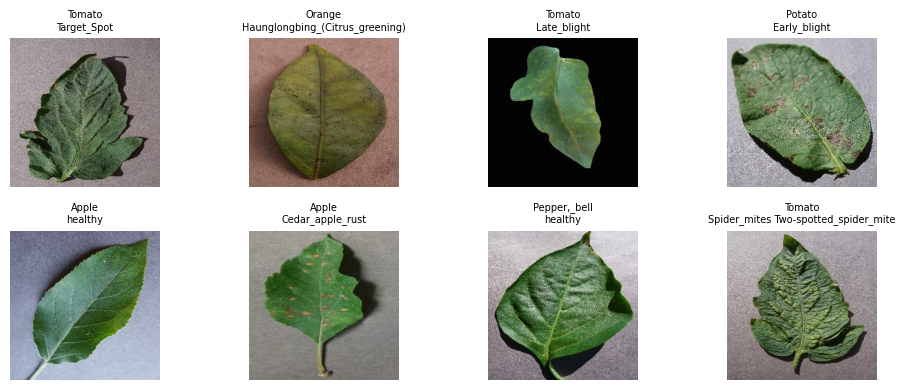

In [5]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True, with_info=True)
class_names = info.features["label"].names
NUM_CLASSES = len(class_names)
print(NUM_CLASSES, "classes;", info.splits["train"].num_examples, "images")

def prep(img, label):
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.float32), label   # raw 0-255; scaling happens inside the model

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.map(prep, AUTOTUNE).shuffle(2000, seed=SEED).batch(BATCH).prefetch(AUTOTUNE)
val_ds   = val_raw.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test_ds  = test_raw.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

plt.figure(figsize=(10, 4))
for i, (img, lbl) in enumerate(train_raw.take(8)):
    plt.subplot(2, 4, i + 1); plt.imshow(img); plt.title(class_names[lbl].replace("___", "\n"), fontsize=7); plt.axis("off")
plt.tight_layout(); plt.show()

## 3. Model: MobileNetV2 + augmentation (augmentation makes it more robust to real-world phone photos)

In [6]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augment")

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input((IMG, IMG, 3))
x = augment(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # MobileNetV2 expects [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary(show_trainable=False)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Train (head first, then fine-tune the top layers)

In [7]:
cb = [tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_accuracy"),
      tf.keras.callbacks.ReduceLROnPlateau(patience=1, factor=0.3)]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb)

# Fine-tune the last ~30 layers at a low learning rate
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 109s 72ms/step - accuracy: 0.8159 - loss: 0.6440 - val_accuracy: 0.9079 - val_loss: 0.3171 - learning_rate: 0.0010
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 102s 74ms/step - accuracy: 0.8920 - loss: 0.3394 - val_accuracy: 0.9251 - val_loss: 0.2463 - learning_rate: 0.0010
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 102s 73ms/step - accuracy: 0.9011 - loss: 0.3077 - val_accuracy: 0.9206 - val_loss: 0.2435 - learning_rate: 0.0010
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 101s 73ms/step - accuracy: 0.9068 - loss: 0.2863 - val_accuracy: 0.9214 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 139s 94ms/step - accuracy: 0.8486 - loss: 0.5210 - val_accuracy: 0.9302 - val_loss: 0.2104 - learning_rate: 1.0000e-05
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 127s 92ms/step - accuracy: 0.9079 - loss: 0.2820 - val_accuracy: 0.9403 - val_loss: 0.1809 - learning_rate: 1.0000e-05
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 126s 92ms/step 

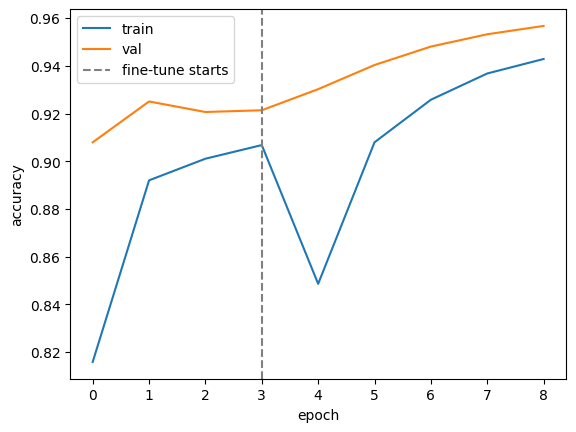

In [8]:
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(vacc, label="val")
plt.axvline(len(h1.history["accuracy"]) - 1, ls="--", c="gray", label="fine-tune starts")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.show()

## 5. Evaluate on the held-out test set

Test accuracy: 0.9593001841620626
                                               precision    recall  f1-score   support

                           Apple___Apple_scab      0.982     0.931     0.956        58
                            Apple___Black_rot      0.985     1.000     0.992        65
                     Apple___Cedar_apple_rust      1.000     1.000     1.000        25
                              Apple___healthy      0.975     1.000     0.988       159
                          Blueberry___healthy      0.992     0.985     0.989       133
                             Cherry___healthy      0.978     0.989     0.983        90
                      Cherry___Powdery_mildew      0.990     0.980     0.985       100
   Corn___Cercospora_leaf_spot Gray_leaf_spot      0.875     0.750     0.808        56
                           Corn___Common_rust      0.992     0.992     0.992       127
                               Corn___healthy      1.000     1.000     1.000       112
        

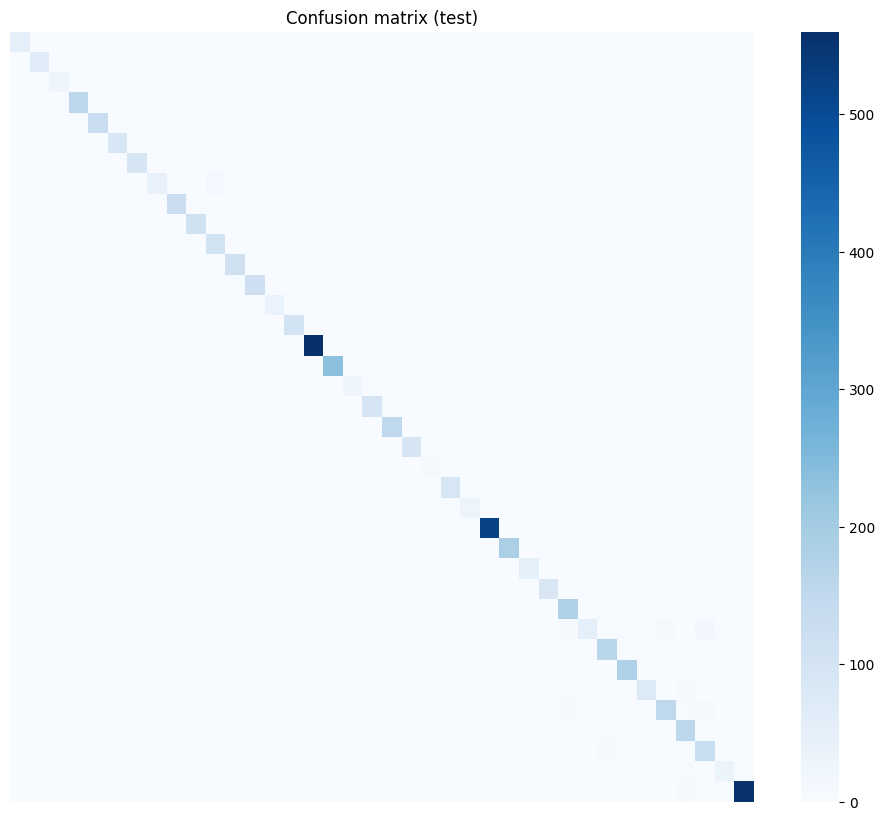

In [9]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probs = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(1)
print("Test accuracy:", (y_true == y_pred).mean())
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10)); sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("Confusion matrix (test)"); plt.show()

## 6. Uncertainty: "I don't know" instead of guessing

We abstain when the top softmax probability is below a threshold. The **coverage-accuracy curve** shows the trade-off:
a higher threshold means fewer answered photos but higher accuracy on those answered.

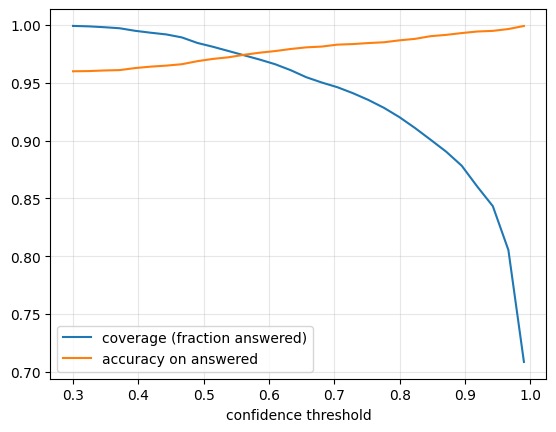

At 0.8: answers 92.0% of photos, accuracy on answered = 0.987


In [10]:
conf = probs.max(1)
thresholds = np.linspace(0.3, 0.99, 30)
coverage, acc_answered = [], []
for t in thresholds:
    m = conf >= t
    coverage.append(m.mean())
    acc_answered.append((y_pred[m] == y_true[m]).mean() if m.any() else np.nan)

plt.plot(thresholds, coverage, label="coverage (fraction answered)")
plt.plot(thresholds, acc_answered, label="accuracy on answered")
plt.xlabel("confidence threshold"); plt.legend(); plt.grid(alpha=.3); plt.show()

THRESHOLD = 0.80   # choose from the curve for your use case
m = conf >= THRESHOLD
print(f"At {THRESHOLD}: answers {m.mean():.1%} of photos, accuracy on answered = {(y_pred[m]==y_true[m]).mean():.3f}")

### Out-of-distribution check
Photos that are *not leaves* should be rejected. Quick test: feed random noise and a non-leaf image and see the confidence.
Softmax can be overconfident on junk, so the deployed app also uses an **entropy** check and (recommended) a small "is this a leaf?" gate.

In [11]:
def entropy(p): return -(p * np.log(p + 1e-9)).sum(-1)

noise = np.random.randint(0, 255, (8, IMG, IMG, 3)).astype("float32")
pn = model.predict(noise, verbose=0)
print("Noise  -> mean conf %.2f, mean entropy %.2f" % (pn.max(1).mean(), entropy(pn).mean()))
print("Real   -> mean conf %.2f, mean entropy %.2f" % (conf.mean(), entropy(probs).mean()))

Noise  -> mean conf 0.86, mean entropy 0.49
Real   -> mean conf 0.96, mean entropy 0.14


## 7. Export to TensorFlow Lite (quantized for phones)

In [12]:
os.makedirs("export", exist_ok=True)
model.save("export/model.keras")

# (a) float32
conv = tf.lite.TFLiteConverter.from_keras_model(model)
open("export/model_fp32.tflite", "wb").write(conv.convert())

# (b) dynamic-range quantization (~4x smaller)
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
open("export/model_dynamic.tflite", "wb").write(conv.convert())

# (c) float16 quantization
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.target_spec.supported_types = [tf.float16]
open("export/model_fp16.tflite", "wb").write(conv.convert())

json.dump(class_names, open("export/labels.json", "w"))
for f in sorted(os.listdir("export")):
    print(f"{f:25s} {os.path.getsize('export/'+f)/1e6:6.2f} MB")

Saved artifact at '/tmp/tmp7p_x7v2t'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  132834107673104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186166480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186166672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186166288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186168592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186167056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186164368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186164560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186164176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186168400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132831186

### Verify the TFLite model matches Keras (accuracy + latency)

In [13]:
import time
def tflite_eval(path, n=500):
    it = tf.lite.Interpreter(model_path=path); it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    correct, times = 0, []
    for img, lbl in test_raw.take(n):
        x = tf.image.resize(img, (IMG, IMG)).numpy()[None].astype("float32")
        it.set_tensor(inp["index"], x)
        t = time.perf_counter(); it.invoke(); times.append(time.perf_counter() - t)
        correct += int(it.get_tensor(out["index"]).argmax() == lbl.numpy())
    return correct / n, np.mean(times) * 1000

for name in ["model_fp32", "model_dynamic", "model_fp16"]:
    a, ms = tflite_eval(f"export/{name}.tflite")
    print(f"{name:15s} acc={a:.3f}  latency={ms:.1f} ms (Colab CPU)")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


model_fp32      acc=0.950  latency=17.5 ms (Colab CPU)
model_dynamic   acc=0.946  latency=20.9 ms (Colab CPU)
model_fp16      acc=0.948  latency=8.9 ms (Colab CPU)


## 8. Deployment files

We generate everything needed: a **Streamlit app**, `requirements.txt`, a **Dockerfile**, and a **README** (which doubles as the Hugging Face Space config).

In [14]:
os.makedirs("deploy", exist_ok=True)
!cp export/model_dynamic.tflite deploy/model.tflite
!cp export/labels.json deploy/labels.json

In [15]:
%%writefile deploy/app.py
import json
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image, ImageOps

IMG = 224
CONF_THRESHOLD = 0.80
ENTROPY_MAX = 1.0

st.set_page_config(page_title="Crop Doctor", page_icon="🌿")
st.title("🌿 Crop Disease Detector")
st.caption("Runs a compact model with no internet needed for inference. "
           "It will say 'uncertain' instead of guessing.")

@st.cache_resource
def load():
    it = tf.lite.Interpreter(model_path="model.tflite")
    it.allocate_tensors()
    return it, json.load(open("labels.json"))

interp, labels = load()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

def predict(img: Image.Image):
    img = ImageOps.exif_transpose(img).convert("RGB").resize((IMG, IMG))
    x = np.asarray(img, dtype="float32")[None]
    interp.set_tensor(inp["index"], x)
    interp.invoke()
    return interp.get_tensor(out["index"])[0]

def pretty(name):
    crop, cond = name.split("___")
    return crop.replace("_", " "), cond.replace("_", " ")

src = st.radio("Image source", ["Camera", "Upload"], horizontal=True)
file = st.camera_input("Take a photo of one leaf") if src == "Camera" \
    else st.file_uploader("Upload a leaf photo", type=["jpg", "jpeg", "png"])

if file:
    img = Image.open(file)
    st.image(img, use_container_width=True)
    p = predict(img)
    order = p.argsort()[::-1][:3]
    conf = float(p[order[0]])
    ent = float(-(p * np.log(p + 1e-9)).sum())

    if conf < CONF_THRESHOLD or ent > ENTROPY_MAX:
        st.warning(f"⚠️ Uncertain (confidence {conf:.0%}). "
                   "Retake the photo (single leaf, good light, fill the frame) "
                   "or ask a local agricultural expert.")
    else:
        crop, cond = pretty(labels[order[0]])
        if cond.lower() == "healthy":
            st.success(f"✅ {crop}: looks healthy ({conf:.0%})")
        else:
            st.error(f"🦠 {crop}: {cond} ({conf:.0%})")
            st.info("Confirm with an extension officer before applying any treatment.")

    with st.expander("Top-3 predictions"):
        for i in order:
            c, d = pretty(labels[i])
            st.write(f"{c} - {d}: {p[i]:.1%}")
st.divider()
st.caption("Trained on PlantVillage (lab-style images). Accuracy on field photos may be lower.")

Writing deploy/app.py


In [16]:
%%writefile deploy/requirements.txt
streamlit==1.39.0
tensorflow-cpu==2.17.0
numpy<2
pillow

Writing deploy/requirements.txt


In [17]:
%%writefile deploy/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 7860
CMD ["streamlit", "run", "app.py", "--server.port=7860", "--server.address=0.0.0.0"]

Writing deploy/Dockerfile


In [18]:
%%writefile deploy/README.md
---
title: Crop Disease Detector
emoji: 🌿
colorFrom: green
colorTo: yellow
sdk: docker
app_port: 7860
pinned: false
---
# Crop Disease Detector
Offline-capable, uncertainty-aware plant disease classifier (MobileNetV2 -> TFLite).

Writing deploy/README.md


### Quick local test of the app (optional, inside Colab)

In [19]:
!cd deploy && nohup streamlit run app.py --server.port 8501 --server.headless true > /tmp/st.log 2>&1 &
import time; time.sleep(6); print(open("/tmp/st.log").read()[-400:])
# To view it in Colab: !npx localtunnel --port 8501   (or just test after deploying)



2026-10-22 23:22:52.449 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.142.211.12:8501

  Stopping...



## 9. Package and download

In [20]:
!cd deploy && zip -r ../crop_disease_deploy.zip . && cd ..
from google.colab import files
files.download("crop_disease_deploy.zip")
files.download("export/model_dynamic.tflite")   # for Android/iOS

  adding: app.py (deflated 48%)
  adding: README.md (deflated 22%)
  adding: requirements.txt (deflated 2%)
  adding: labels.json (deflated 63%)
  adding: model.tflite (deflated 15%)
  adding: Dockerfile (deflated 23%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Deployment options

### A) Hugging Face Spaces (free, easiest)
1. Create an account at huggingface.co -> **New Space** -> SDK: **Docker**.
2. Upload everything inside `deploy/` (app.py, model.tflite, labels.json, requirements.txt, Dockerfile, README.md).
3. The Space builds automatically and gives you a public URL.

### B) Docker anywhere (Render, Railway, a VPS, local)
```bash
cd deploy
docker build -t crop-doctor .
docker run -p 7860:7860 crop-doctor
```

### C) Truly offline on Android
- Use `model_dynamic.tflite` + `labels.json` in an Android app with the **TensorFlow Lite Task Library** or **Flutter `tflite_flutter`**.
- Input: 224x224 RGB float32 in 0-255 (scaling is inside the model). Output: 38 probabilities.
- Apply the same threshold logic: show "uncertain" when max prob < 0.80.

### D) Close the real-world gap (strongest upgrade)
- Add **PlantDoc** (field photos) or your own photos, fine-tune again, and report accuracy separately for lab vs field images.
- Add a small binary "leaf / not leaf" classifier to reject irrelevant photos.
- Calibrate probabilities (temperature scaling on the validation set) before choosing the threshold.
- Add Arabic/English UI strings for local farmers.

## 11. Report checklist
- Test accuracy, macro-F1, per-class confusion
- Coverage-accuracy curve and chosen threshold
- Model size and latency: fp32 vs dynamic vs fp16
- Failure cases (similar diseases, bad lighting) with images
- Limitations: lab-style data, no treatment advice, expert confirmation required